# Part 1 -- Data Cleaning, EDA & Split Generation
**Dataset:** `gretelai/synthetic_text_to_sql` -- 100,000 train + 5,851 test rows  
**Goal:** Clean both splits, generate stratified train/val/test ID files, produce EDA plots.

Run this notebook top-to-bottom. Runtime is under 5 minutes.  
All cleaning logic lives in `data.py`; this notebook calls it and displays the results.

## 0. Setup

In [4]:
import sys, json, time, random
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

sys.path.insert(0, str(Path('.').resolve()))
import data
from config import CONFIG, SEED

_notebook_start = time.time()
print("Imports OK.")
print(f"Dataset  : {CONFIG['dataset']}")
print(f"Seed     : {SEED}")
print(f"QUICK_RUN: {CONFIG.get('QUICK_RUN', True)}")

Imports OK.
Dataset  : gretelai/synthetic_text_to_sql
Seed     : 42
QUICK_RUN: True


## 1. Raw Dataset Overview

In [5]:
ds = data.load_data()

print(f"Official train split : {len(ds['train']):>8,d} rows")
print(f"Official test split  : {len(ds['test']):>8,d} rows")
print(f"\nColumns: {ds['train'].column_names}")

# Null / blank check on key columns
required = ['id', 'domain', 'sql_complexity', 'sql_prompt', 'sql_context', 'sql']
print("\nMissing / blank values in key columns (train):")
for col in required:
    n = sum(1 for v in ds['train'][col] if v is None or str(v).strip() == '')
    status = '[OK]' if n == 0 else f'[WARN] {n}'
    print(f"  {col:<25} {status}")

print("\nSample test row:")
ex = ds['test'][0]
for col in required:
    print(f"  {col:<15}: {str(ex[col])[:80]}")

README.md:   0%|          | 0.00/8.19k [00:00<?, ?B/s]

synthetic_text_to_sql_train.snappy.parqu(…): reconstructing file:   0%|          |  0.00B / 32.4MB            

synthetic_text_to_sql_train.snappy.parqu(…): downloading bytes:           |  0.00B            

synthetic_text_to_sql_test.snappy.parque(…): reconstructing file:   0%|          |  0.00B / 1.90MB            

synthetic_text_to_sql_test.snappy.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5851 [00:00<?, ? examples/s]

Official train split :  100,000 rows
Official test split  :    5,851 rows

Columns: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation']

Missing / blank values in key columns (train):
  id                        [OK]
  domain                    [OK]
  sql_complexity            [OK]
  sql_prompt                [OK]
  sql_context               [OK]
  sql                       [OK]

Sample test row:
  id             : 1
  domain         : artificial intelligence
  sql_complexity : basic SQL
  sql_prompt     : What is the average explainability score of creative AI applications in 'Europe'
  sql_context    : CREATE TABLE creative_ai (application_id INT, name TEXT, region TEXT, explainabi
  sql            : SELECT AVG(explainability_score) FROM creative_ai WHERE region IN ('Europe', 'No


## 2. Manual Exclusions
Pre-flagged examples that pass all automated checks but are semantically wrong.  
Add new flagged IDs directly to `excluded_ids.json` before re-running the notebook.

In [6]:
excluded_path = Path(CONFIG.get('excluded_ids_path', 'excluded_ids.json'))
excluded_ids  = data.load_excluded_ids(excluded_path)

print(f"Manual exclusions loaded: {len(excluded_ids)} IDs from {excluded_path}")

try:
    with open(excluded_path) as f:
        excl = json.load(f)
    print(f"\n  Test exclusions : {len(excl.get('test_exclusions', []))}")
    print(f"  Train exclusions: {len(excl.get('train_exclusions', []))}")
    for e in excl.get('test_exclusions', []):
        print(f"\n  [Pre-flagged] ID {e['id']} ({e['split']})")
        print(f"  Reason: {e['reason']}")
except FileNotFoundError:
    print("excluded_ids.json not found -- proceeding without manual exclusions.")

Manual exclusions loaded: 1 IDs from excluded_ids.json

  Test exclusions : 1
  Train exclusions: 0

  [Pre-flagged] ID 4323 (test)
  Reason: Gold query ignores the BRICS country filter — performs an inner join without a WHERE clause, returning all rows from military_innovation instead of only BRICS countries.


## 3. Clean Official Test Split (5,851 rows)
Every removed example is logged with its reason so you can verify no valid data was dropped.

In [7]:
print(f"Cleaning official test split ({len(ds['test']):,} rows)...\n")
clean_test, test_log = data.clean_split(ds['test'], 'test', excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_test):,} clean  |  {len(test_log):,} removed")

def categorize(reason: str) -> str:
    r = reason.lower()
    if 'manual'           in r: return 'Manual exclusion'
    if 'non-read'         in r or 'does not start' in r: return 'Write / non-SELECT op'
    if 'context setup'    in r: return 'Context setup error'
    if 'sql execution'    in r: return 'SQL execution error'
    if 'empty result'     in r: return 'Empty result ([])'
    if 'trivial'          in r: return 'Trivial result'
    return 'Other'

test_reason_counts = Counter(categorize(e['reason']) for e in test_log)
print("\nRemoval breakdown -- test split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in test_reason_counts.most_common():
    pct = count / len(ds['test']) * 100
    print(f"  {reason:<40} {count:>6,d}  {pct:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_test):,} ({len(clean_test)/len(ds['test'])*100:.1f}%)")

Cleaning official test split (5,851 rows)...

  test: 5,851/5,851 | clean: 3,078 | removed: 2,773

Result: 3,078 clean  |  2,773 removed

Removal breakdown -- test split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                       1,052   18.0%
  Write / non-SELECT op                       613   10.5%
  Empty result ([])                           592   10.1%
  Trivial result                              348    5.9%
  Context setup error                         167    2.9%
  Manual exclusion                              1    0.0%

  Total clean pool: 3,078 (52.6%)


In [8]:
# Show 2 examples per removal category so you can spot-check the cleaning logic
print("Sample removed examples (2 per category):\n")
shown = Counter()
MAX_PER_CAT = 2

for entry in test_log:
    cat = categorize(entry['reason'])
    if shown[cat] >= MAX_PER_CAT:
        continue
    shown[cat] += 1
    print(f"[REMOVED] ID: {entry['id']} | {entry['reason']}")
    print(f"  Prompt : {entry['sql_prompt']}")
    print(f"  SQL    : {entry['sql']}")
    print()

Sample removed examples (2 per category):

[REMOVED] ID: 2 | Non-read operation — query starts with DELETE
  Prompt : Delete all records of rural infrastructure projects in Indonesia that have a completion date before 
  SQL    : DELETE FROM rural_infrastructure WHERE country = 'Indonesia' AND completion_date < '2010-01-01';

[REMOVED] ID: 6 | Non-read operation — query starts with INSERT
  Prompt : Add a new attorney named 'Oliver Martinez' with email 'oliver.martinez@lawfirm.com' and phone '555-5
  SQL    : INSERT INTO attorneys (attorney_name, attorney_email, attorney_phone) VALUES ('Oliver Martinez', 'ol

[REMOVED] ID: 8 | Gold query returns trivial result: [(None,)]
  Prompt : What is the total cost of all climate communication projects that ended after 2010 in 'Antarctica'?
  SQL    : SELECT SUM(total_cost) FROM climate_communication WHERE location = 'Antarctica' AND end_date >= '201

[REMOVED] ID: 9 | Gold query returns empty result ([])
  Prompt : List all marine species with t

## 4. Clean Official Train Split (100,000 rows)
Same checks applied. Only a summary is shown here -- printing 48k removal reasons would be unreadable.

In [9]:
print(f"Cleaning official train split ({len(ds['train']):,} rows)...\n")
clean_train, train_log = data.clean_split(ds['train'], 'train', excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_train):,} clean  |  {len(train_log):,} removed")

train_reason_counts = Counter(categorize(e['reason']) for e in train_log)
print("\nRemoval breakdown -- train split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in train_reason_counts.most_common():
    pct = count / len(ds['train']) * 100
    print(f"  {reason:<40} {count:>6,d}  {pct:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_train):,} ({len(clean_train)/len(ds['train'])*100:.1f}%)")

Cleaning official train split (100,000 rows)...

  train: 100,000/100,000 | clean: 52,181 | removed: 47,819

Result: 52,181 clean  |  47,819 removed

Removal breakdown -- train split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                      19,392   19.4%
  Write / non-SELECT op                    10,243   10.2%
  Empty result ([])                         9,621    9.6%
  Trivial result                            6,033    6.0%
  Context setup error                       2,529    2.5%
  Manual exclusion                              1    0.0%

  Total clean pool: 52,181 (52.2%)


## 5. Removal Analysis Plot

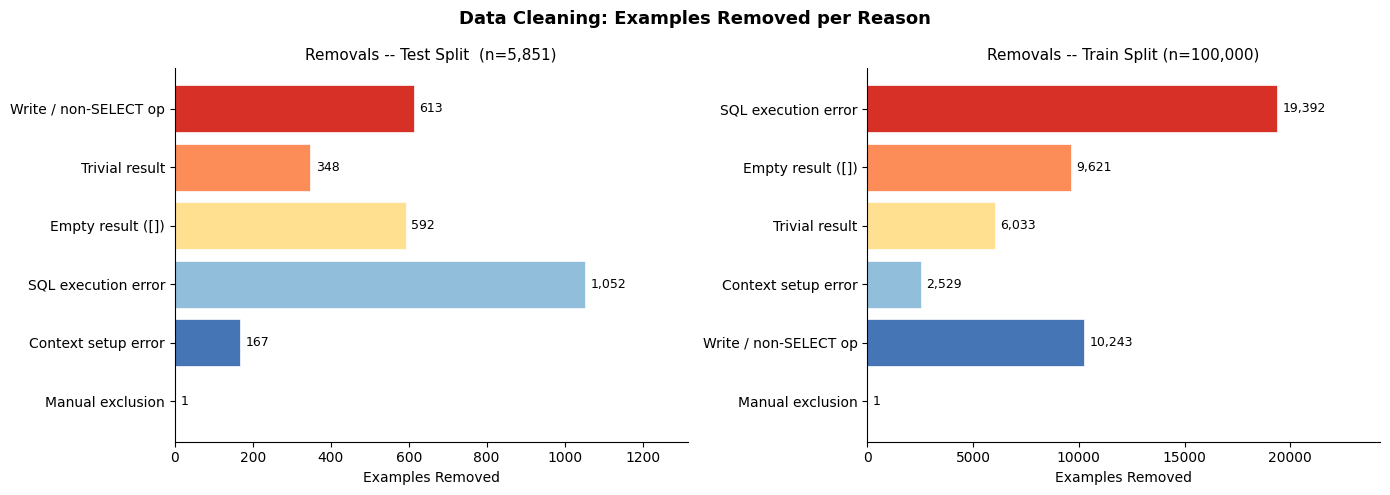

Saved: cleaning_removal_reasons.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ['#d73027', '#fc8d59', '#fee090', '#91bfdb', '#4575b4', '#74add1', '#313695']

for ax, (counts, split_name, raw_total) in zip(axes, [
    (test_reason_counts,  f'Test Split  (n={len(ds["test"]):,})',   len(ds['test'])),
    (train_reason_counts, f'Train Split (n={len(ds["train"]):,})', len(ds['train'])),
]):
    labels = list(counts.keys())
    values = list(counts.values())
    colors = palette[:len(labels)]
    bars = ax.barh(labels, values, color=colors, edgecolor='white', linewidth=0.5)
    ax.set_xlabel('Examples Removed')
    ax.set_title(f'Removals -- {split_name}', fontsize=11)
    ax.bar_label(bars, labels=[f'{v:,}' for v in values], padding=4, fontsize=9)
    ax.set_xlim(0, max(values) * 1.25 if values else 1)
    ax.invert_yaxis()
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Data Cleaning: Examples Removed per Reason', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('cleaning_removal_reasons.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved: cleaning_removal_reasons.png")

## 6. Generate Clean Splits
Workflow:
  1. Sample 200 clean test examples from clean_test, stratified by sql_complexity.
  2. First 20 test IDs form the QUICK_RUN subset.
  3. Sample 200 clean validation examples from the remaining clean test candidates.
  4. Save test_ids.json, val_ids.json, and train_ids.json.

In [11]:
rng       = random.Random(SEED)
test_size = CONFIG.get('test_size', 200)
val_size  = CONFIG.get('val_size',  200)

test_rows, remainder = data.stratified_sample(clean_test,  test_size, rng)
val_rows,  _         = data.stratified_sample(remainder,   val_size,  rng)

test_ids  = [r['id'] for r in test_rows]
val_ids   = [r['id'] for r in val_rows]
train_ids = [r['id'] for r in clean_train]

# Save ID files
test_ids_path  = Path(CONFIG.get('test_ids_path',  'test_ids.json'))
val_ids_path   = Path(CONFIG.get('val_ids_path',   'val_ids.json'))
train_ids_path = Path(CONFIG.get('train_ids_path', 'train_ids.json'))

data.save_json_list(test_ids_path,  test_ids)
data.save_json_list(val_ids_path,   val_ids)
data.save_json_list(train_ids_path, train_ids)

# Disjointness checks
test_set, val_set = set(test_ids), set(val_ids)
assert not (test_set & val_set), "ERROR: test and val share IDs!"
print("Disjointness checks:")
print(f"  test & val ID overlap: {len(test_set & val_set)} [OK]")

print(f"\nFinal split sizes:")
print(f"  test_ids.json  : {len(test_ids):,} examples  (first 20 = QUICK_RUN)")
print(f"  val_ids.json   : {len(val_ids):,} examples")
print(f"  train_ids.json : {len(train_ids):,} examples")
print(f"\nQUICK_RUN subset (first 20 test IDs):")
print(f"  {test_ids[:20]}")


Disjointness checks:
  test & val ID overlap: 0 [OK]

Final split sizes:
  test_ids.json  : 200 examples  (first 20 = QUICK_RUN)
  val_ids.json   : 200 examples
  train_ids.json : 52,181 examples

QUICK_RUN subset (first 20 test IDs):
  [5610, 3193, 5576, 4929, 4484, 4644, 3510, 2691, 4728, 1684, 4542, 2914, 2740, 4669, 5278, 5323, 109, 1175, 1301, 5194]


In [12]:
# Complexity breakdown per split
test_comp  = Counter(r['sql_complexity'] for r in test_rows)
val_comp   = Counter(r['sql_complexity'] for r in val_rows)
train_comp = Counter(r['sql_complexity'] for r in clean_train)
all_comps  = sorted(set(test_comp) | set(val_comp) | set(train_comp))

print(f"SQL Complexity Distribution:")
print(f"  {'Complexity':<25} {'Train':>9} {'Val':>6} {'Test':>6}")
print("  " + "-" * 52)
for comp in all_comps:
    print(
        f"  {comp:<25} {train_comp.get(comp,0):>9,d} "
        f"{val_comp.get(comp,0):>6,d} {test_comp.get(comp,0):>6,d}"
    )

SQL Complexity Distribution:
  Complexity                    Train    Val   Test
  ----------------------------------------------------
  aggregation                  12,737     49     49
  basic SQL                    26,571    104    102
  multiple_joins                  903      3      4
  set operations                  536      2      2
  single join                   6,873     26     27
  subqueries                    2,606      8      9
  window functions              1,955      8      7


## 7. EDA -- SQL Complexity Distribution

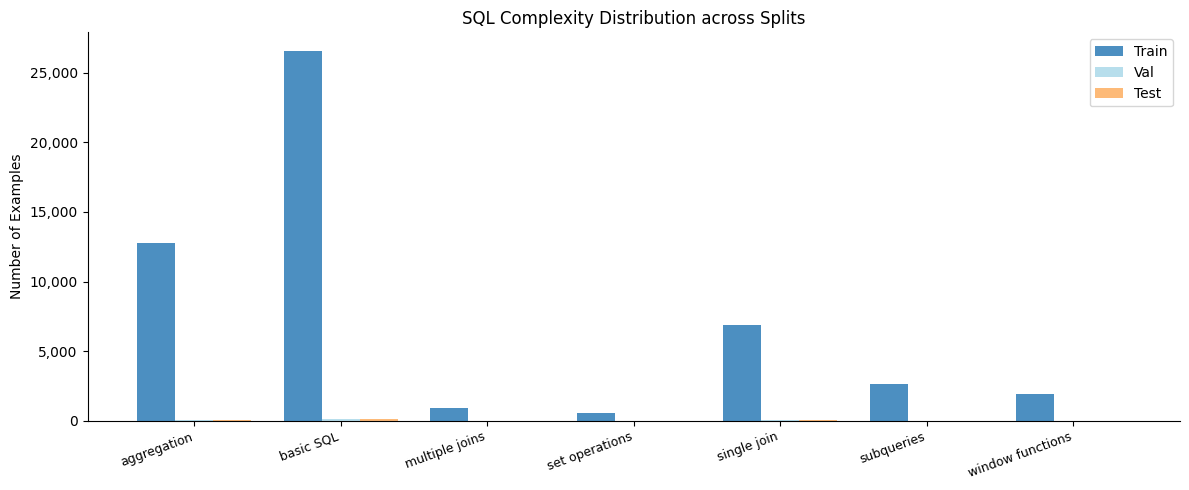

Saved: eda_complexity_distribution.png


In [13]:
fig, ax = plt.subplots(figsize=(12, 5))

comps    = list(all_comps)
x        = range(len(comps))
width    = 0.26
colors   = ['#2c7bb6', '#abd9e9', '#fdae61']

train_vals = [train_comp.get(c, 0) for c in comps]
val_vals   = [val_comp.get(c, 0)   for c in comps]
test_vals  = [test_comp.get(c, 0)  for c in comps]

b1 = ax.bar([i - width for i in x], train_vals, width, label='Train', color=colors[0], alpha=0.85)
b2 = ax.bar([i         for i in x], val_vals,   width, label='Val',   color=colors[1], alpha=0.85)
b3 = ax.bar([i + width for i in x], test_vals,  width, label='Test',  color=colors[2], alpha=0.85)

ax.set_xticks(list(x))
ax.set_xticklabels([c.replace('_', ' ') for c in comps], rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Number of Examples')
ax.set_title('SQL Complexity Distribution across Splits', fontsize=12)
ax.legend()
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('eda_complexity_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved: eda_complexity_distribution.png")

## 8. EDA -- Top 20 Domains (Train)

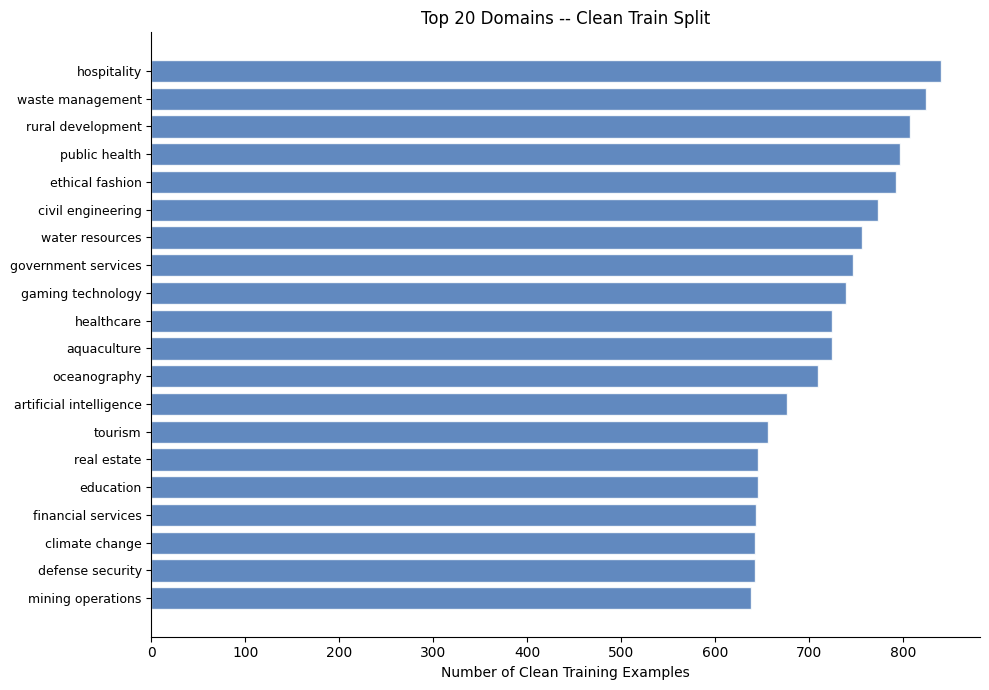

Saved: eda_domain_distribution.png
Total unique domains in clean train: 100


In [14]:
domain_counts = Counter(r['domain'] for r in clean_train)
top20 = domain_counts.most_common(20)
labels, values = zip(*top20)

fig, ax = plt.subplots(figsize=(10, 7))
y = range(len(labels))
ax.barh(list(y), list(values), color='#4575b4', alpha=0.85, edgecolor='white')
ax.set_yticks(list(y))
ax.set_yticklabels(list(labels), fontsize=9)
ax.set_xlabel('Number of Clean Training Examples')
ax.set_title('Top 20 Domains -- Clean Train Split', fontsize=12)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('eda_domain_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
total_domains = len(domain_counts)
print(f"Saved: eda_domain_distribution.png")
print(f"Total unique domains in clean train: {total_domains}")

## 9. EDA -- Prompt & SQL Length Distributions

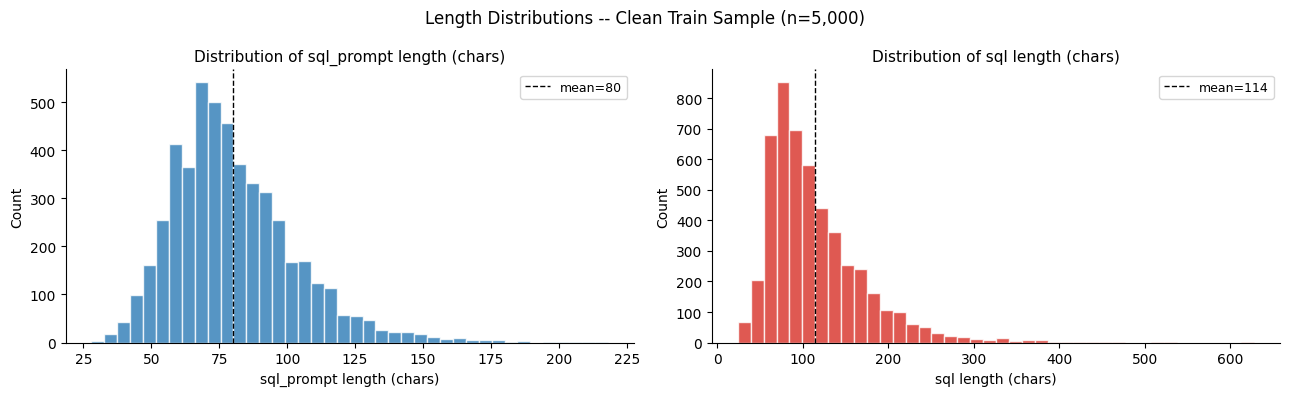

Saved: eda_length_distributions.png


In [15]:
# Sample 5,000 train examples for speed (representative)
import random as _rnd
_rnd.seed(SEED)
sample = _rnd.sample(clean_train, min(5000, len(clean_train)))

prompt_lens = [len(r['sql_prompt']) for r in sample]
sql_lens    = [len(r['sql'])        for r in sample]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, data_vals, label, color in zip(
    axes,
    [prompt_lens, sql_lens],
    ['sql_prompt length (chars)', 'sql length (chars)'],
    ['#2c7bb6', '#d73027'],
):
    ax.hist(data_vals, bins=40, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(sum(data_vals)/len(data_vals), color='black', linestyle='--', linewidth=1,
               label=f'mean={sum(data_vals)/len(data_vals):.0f}')
    ax.set_xlabel(label)
    ax.set_ylabel('Count')
    ax.set_title(f'Distribution of {label}', fontsize=11)
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Length Distributions -- Clean Train Sample (n=5,000)', fontsize=12)
plt.tight_layout()
plt.savefig('eda_length_distributions.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved: eda_length_distributions.png")

## 10. Overlap & Leakage Report
Verifies that test and val questions never appear in training data or the RAG index.

In [16]:
test_prompts  = {r['sql_prompt'] for r in test_rows}
val_prompts   = {r['sql_prompt'] for r in val_rows}
train_prompts = {r['sql_prompt'] for r in clean_train}

print("Prompt overlap (must be 0):")
print(f"  test  & train prompt overlap: {len(test_prompts  & train_prompts):,}")
print(f"  val   & train prompt overlap: {len(val_prompts   & train_prompts):,}")
print(f"  test  & val   prompt overlap: {len(test_prompts  & val_prompts):,}")

# sql_context (table schema) overlap -- shared tables are OK but worth reporting
test_contexts  = {r['sql_context'] for r in test_rows}
val_contexts   = {r['sql_context'] for r in val_rows}
train_contexts = {r['sql_context'] for r in clean_train}

print("\nsql_context (table schema) overlap:")
print(f"  test  & train context overlap: {len(test_contexts  & train_contexts):,}  (shared table schemas)")
print(f"  val   & train context overlap: {len(val_contexts   & train_contexts):,}  (shared table schemas)")
print("  Note: shared schemas are expected in a synthetic dataset;")
print("  what matters is that prompts and IDs do not overlap (all 0 above).")

print("\nLeakage safeguard:")
print("  * test_ids.json and val_ids.json are disjoint from train_ids.json")
print("  * Teammates building RAG index / LoRA: use train_ids.json only")
print("  * Do not index or train on any ID from test_ids.json or val_ids.json")

Prompt overlap (must be 0):
  test  & train prompt overlap: 0
  val   & train prompt overlap: 0
  test  & val   prompt overlap: 0

sql_context (table schema) overlap:
  test  & train context overlap: 16  (shared table schemas)
  val   & train context overlap: 21  (shared table schemas)
  Note: shared schemas are expected in a synthetic dataset;
  what matters is that prompts and IDs do not overlap (all 0 above).

Leakage safeguard:
  * test_ids.json and val_ids.json are disjoint from train_ids.json
  * Teammates building RAG index / LoRA: use train_ids.json only
  * Do not index or train on any ID from test_ids.json or val_ids.json


## 11. SQL Harness Self-Tests
Four assertions that verify `run_sql` and `same_result` behave correctly.

In [17]:
data.self_test_harness()
print("\nHarness self-tests complete.")

All 4 self-tests passed [OK]

Harness self-tests complete.


## 12. Filter Report

In [18]:
report = data.generate_filter_report(
    test_log=test_log,
    train_log=train_log,
    test_ids=test_ids,
    val_ids=val_ids,
    train_ids=train_ids,
    test_raw=len(ds['test']),
    train_raw=len(ds['train']),
)

print("\n=== Filter Report Summary ===")
print(f"\nTest split ({report['test_split']['raw_total']:,} raw):")
for reason, count in report['test_split']['removed_by_reason'].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean pool                  : {report['test_split']['clean_pool_size']:,}")

print(f"\nTrain split ({report['train_split']['raw_total']:,} raw):")
for reason, count in report['train_split']['removed_by_reason'].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean total                 : {report['train_split']['clean_total']:,}")

print(f"\nFinal splits:")
for k, v in report['final_splits'].items():
    print(f"  {k:<25}: {v:,}")

print(f"\nManual audit status: {report['manual_audit']['status']}")

Filter report saved -> filter_report.json

=== Filter Report Summary ===

Test split (5,851 raw):
  write_or_non_select         : 613
  trivial_result              : 348
  empty_result                : 592
  sql_execution_error         : 1,052
  context_setup_error         : 167
  manual_exclusion            : 1
  Clean pool                  : 3,078

Train split (100,000 raw):
  sql_execution_error         : 19,392
  empty_result                : 9,621
  trivial_result              : 6,033
  context_setup_error         : 2,529
  write_or_non_select         : 10,243
  manual_exclusion            : 1
  Clean total                 : 52,181

Final splits:
  test                     : 200
  val                      : 200
  train_clean_total        : 52,181
  quick_run_subset         : 20

Manual audit status: pending manual review by team member (1 example pre-flagged as reference)


## 13. Runtime Summary

In [19]:
elapsed = time.time() - _notebook_start
print(f"Notebook completed in {elapsed:.1f} seconds ({elapsed/60:.1f} minutes)")
print(f"All cells ran successfully. Files saved:")
for fname in ['test_ids.json', 'val_ids.json', 'train_ids.json',
              'excluded_ids.json', 'filter_report.json',
              'cleaning_removal_reasons.png', 'eda_complexity_distribution.png',
              'eda_domain_distribution.png', 'eda_length_distributions.png']:
    p = Path(fname)
    status = f"{p.stat().st_size:,} bytes" if p.exists() else "NOT FOUND"
    print(f"  {fname:<40} {status}")


Notebook completed in 59.7 seconds (1.0 minutes)
All cells ran successfully. Files saved:
  test_ids.json                            1,560 bytes
  val_ids.json                             1,559 bytes
  train_ids.json                           463,819 bytes
  excluded_ids.json                        660 bytes
  filter_report.json                       1,214 bytes
  cleaning_removal_reasons.png             67,563 bytes
  eda_complexity_distribution.png          49,026 bytes
  eda_domain_distribution.png              65,767 bytes
  eda_length_distributions.png             54,875 bytes
